# Multi-agent task assignment

**Recipe 49** · Level 4 (Advanced) · Decision type: `Score`

Score each agent's suitability for a subtask so a deterministic scheduler can assign work under capability, dependency, and budget constraints.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

A suitability scorer for (agent, subtask) pairs, one `Score` per pair, over a rubric with five levels written out in order. Jev's answer never decides who gets assigned: a deterministic Python scheduler combines every pair's score with three things Jev is never asked about and never shown -- which agents hold the skill a subtask needs (capability), which subtasks must finish before another can start (dependency), and how much work is left in each agent's budget -- and assigns work only when all three hold and the chosen agent's answer is confident enough. The central claim this recipe backs with a test, not a sentence, is that those three constraints hold for *any* scores Jev could have returned.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the stored answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same question definition and changes nothing else. `run_header` states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a line that is not a result to report, such as a number from `validation`, the split settings are chosen on, or a count of the items the frozen rule queues or would queue. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    evaluate_outcomes,
    score_level,
    select_confidence_threshold,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_risk_coverage,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
questions = helpers.build_questions()

# One request per (agent, subtask) pair; every example id is already unique to one pair, so
# caching by example id is enough to guarantee exactly one request per example in live mode.
_answered = {}


def decide(example):
    if example.id not in _answered:
        _answered[example.id] = backend.decide(helpers.build_state(example.fields), questions)[
            "suitability"
        ]
    return _answered[example.id]


# N for the header is the number of SCORED pairs (validation + test); the two demo pairs are
# shown but never scored against a gold label.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: "a number from the validation split is a selection step, not a
# result." This label does not depend on run mode, unlike `check` above.
selection = " (a selection step, not a reported result)"

run_header(49, "Multi-agent task assignment", backend=backend, n_examples=len(scored))

Recipe 49: Multi-agent task assignment
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 72 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Each example in `fixtures/inputs.jsonl` carries `fields`: a scenario name, an agent id, a subtask id, and two pieces of plain text -- the agent's track record and the subtask's description. `build_state` passes on only those two text fields; everything structured (which skill the subtask needs, which skills the agent holds, the agent's remaining budget, the subtask's dependencies) stays in Python and is never part of what Jev sees. The demo example below asks Jev to judge an agent for a subtask that needs a skill ("security") nobody on either roster holds -- Jev is never told that; Python already knows it from structured data, and the scheduler below enforces it regardless of what Jev answers.

In [2]:
import json

demo = [e for e in examples if e.split == "demo"]
example = demo[0]
print("Python has:")
print(json.dumps(example.fields, indent=2))
state = helpers.build_state(example.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "scenario": "demo",
  "agent_id": "nova",
  "subtask_id": "d1-security-review",
  "agent_profile": "Nova has spent the last two years writing backend services and database schemas, including three API redesigns that shipped without a rollback.",
  "subtask_description": "Review the new integration for a security vulnerability before it ships."
}
Jev sees:
{
  "agent_profile": "Nova has spent the last two years writing backend services and database schemas, including three API redesigns that shipped without a rollback.",
  "subtask_description": "Review the new integration for a security vulnerability before it ships."
}


## The questions

There is one question, asked once per (agent, subtask) pair: how suitable is this agent for this subtask, given only its track record and what the subtask needs? A `Score` fits because suitability is a position on an ordered scale, not a choice among unrelated categories. Jev evaluates every level independently against the state (TypeSafe's primitives documentation, S02: "Every level is evaluated separately. The model doesn't see a level's number or its neighbours."), so each of the five levels below is written to stand alone rather than naming the level above or below it. Capability, dependency and budget are never mentioned in the instructions or in any level: Jev is asked for a semantic judgment about fit, and Python owns every hard constraint around it.

In [3]:
suitability = questions["suitability"]
print(suitability.instructions)
for level, description in enumerate(suitability.criteria):
    print(f"  {level}  {description}")

How suitable is this agent for this subtask, based only on the agent's track record and what the subtask needs?
  0  Nothing in the agent's track record resembles this kind of work; attempting the subtask would very likely fail.
  1  The agent's track record is in a related area but does not cover the specific kind of outcome this subtask needs; completing it would take substantial unsupported effort.
  2  The agent's track record covers the general skill this subtask needs, without a completed example of this particular kind of outcome; a workable fit that is not yet demonstrated.
  3  The agent's track record includes a directly comparable completed example of this subtask's kind of outcome; a strong, demonstrated fit.
  4  The agent's track record shows multiple successful completions of exactly this kind of outcome; the best possible fit.


## One answer up close

Two typed answers before any aggregate. The first is nova's answer for `s1-api-schema`, in the "sprint-1" validation scenario: a strong, confident match. The second is the adversarial case this recipe's fixtures were built to exercise: wren's answer for `s2-api-implementation`. Wren holds no coding skill at all -- the gold level for this pair is 1, "tangential" -- but wren's stored answer was written to look confidently excellent anyway (level 4, high confidence), specifically to test whether the scheduler's capability filter holds even when Jev's own score says otherwise.

Nova has spent the last two years writing backend services and database schemas, including three API redesigns that shipped without a rollback.
Define the schema the new API will expose, including field names and types, before any implementation starts.
Score: 3.80 (confidence 0.83)
  0 Nothing in the agent's track record resembles this kind of work; attempting the subtask would
    very likely fail.  0.01  
  1 The agent's track record is in a related area but does not cover the specific kind of outcome
    this subtask needs; completing it would take substantial unsupported effort.  0.02  
  2 The agent's track record covers the general skill this subtask needs, without a completed
    example of this particular kind of outcome; a workable fit that is not yet demonstrated.  0.03  #
  3 The agent's track record includes a directly comparable completed example of this subtask's kind
    of outcome; a strong, demonstrated fit.  0.04  #
  4 The agent's track record shows multiple success

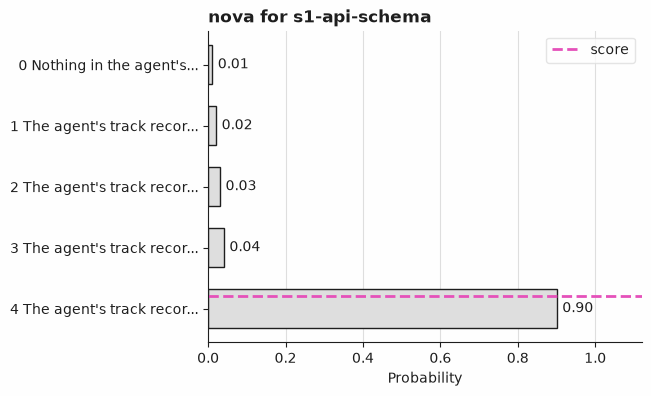

In [4]:
val_examples_by_id = {e.id: e for e in examples if e.split == "validation"}
nova_s1 = val_examples_by_id["v-nova-s1-api-schema"]
print(nova_s1.fields["agent_profile"])
print(nova_s1.fields["subtask_description"])
nova_s1_answer = decide(nova_s1)
show_answer(nova_s1_answer)
plot_answer_probabilities(nova_s1_answer, title="nova for s1-api-schema")

Nova's track record ("writing backend services and database schemas, including three API redesigns") matches `s1-api-schema` directly, and the stored answer puts almost all of its probability on level 4 ("ideal fit"), at high confidence. This is the easy case: a real skill match, judged well.

Wren writes release notes and user-facing documentation, and has a reputation for documentation that the support team can actually use.
Implement the backend service against the schema that was just defined.
Score: 3.97 (confidence 0.97)
  0 Nothing in the agent's track record resembles this kind of work; attempting the subtask would
    very likely fail.  0.00  
  1 The agent's track record is in a related area but does not cover the specific kind of outcome
    this subtask needs; completing it would take substantial unsupported effort.  0.00  
  2 The agent's track record covers the general skill this subtask needs, without a completed
    example of this particular kind of outcome; a workable fit that is not yet demonstrated.  0.01  
  3 The agent's track record includes a directly comparable completed example of this subtask's kind
    of outcome; a strong, demonstrated fit.  0.01  
  4 The agent's track record shows multiple successful completions of exactly this kind of outcome;

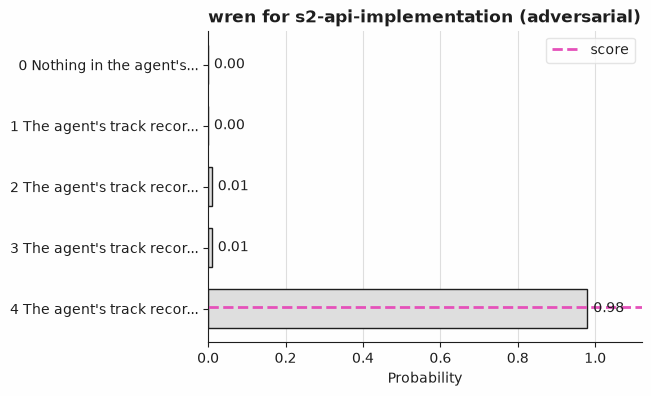

In [5]:
wren_s2 = val_examples_by_id["v-wren-s2-api-implementation"]
print(wren_s2.fields["agent_profile"])
print(wren_s2.fields["subtask_description"])
wren_s2_answer = decide(wren_s2)
show_answer(wren_s2_answer)
plot_answer_probabilities(wren_s2_answer, title="wren for s2-api-implementation (adversarial)")

Wren's own track record is entirely about documentation -- nothing in it resembles implementing a backend service -- yet this stored answer peaks at level 4 with higher confidence than almost any other pair in the fixtures. Nothing here shows that a real Jev call would be swayed this way; the point is narrower and does not depend on that: Python's capability filter, below, never asks whether a score looks confident. It asks whether the agent holds the skill, and wren does not, so wren is never a candidate for `s2-api-implementation` regardless of what this answer says.

## Python's part

`helpers.assign` is the scheduler. For every subtask, in an order that respects every dependency (`helpers.topological_order`, Kahn's algorithm, ties broken by subtask id): if a dependency was not itself assigned, the subtask goes straight to `review` ("a dependency was not assigned") -- no score is even looked at. Otherwise the agent with the highest suitability score is chosen from only those agents who are both capable (hold the required skill) and have enough budget left; if that agent's [confidence](../../docs/glossary.md#confidence-gate) is below the frozen threshold, the subtask goes to [`review`](../../docs/glossary.md#review) ("confidence below the threshold"); otherwise it is `assigned`, and that agent's budget is spent. Running the scheduler on `sprint-1` below with the confidence gate turned off (threshold `0.0`) isolates what capability, dependency and budget alone decide, before confidence enters at all.

In [6]:
from jev_cookbook.simulation import Budget

val_agents, val_subtasks = helpers.VALIDATION_AGENTS, helpers.VALIDATION_SUBTASKS
val_scores = {
    (e.fields["agent_id"], e.fields["subtask_id"]): decide(e)
    for e in examples
    if e.split == "validation"
}
walkthrough = helpers.assign(val_agents, val_subtasks, val_scores, 0.0)
for subtask in val_subtasks:
    d = walkthrough.by_id()[subtask.id]
    if d.outcome == helpers.ASSIGNED:
        print(f"  {subtask.id}: assigned -> {d.agent_id} (confidence {d.confidence:.4f})")
    else:
        print(f"  {subtask.id}: review ({d.reason})")
print("remaining budget:", {k: v["remaining"] for k, v in walkthrough.budget.to_dict().items()})

  s1-api-schema: assigned -> nova (confidence 0.8333)
  s2-api-implementation: assigned -> orin (confidence 0.8333)
  s3-release-notes: assigned -> wren (confidence 0.8333)
  s4-onboarding-guide: assigned -> zephyr (confidence 0.5417)
  s5-perf-tuning: assigned -> iris (confidence 0.8833)
  s6-load-test: review (no eligible agent)
remaining budget: {'nova': 0, 'iris': 0, 'orin': 0, 'wren': 0, 'sable': 1, 'zephyr': 0}


This is the stateful, adversarial case this recipe's fixtures were built to walk through. `s1-api-schema` goes to nova, correctly. `s2-api-implementation` goes to orin, *not* to iris -- orin's stored score (confidently) outranks iris's among the capable agents, even though the gold level says iris is the better fit; wren's adversarial score above never enters the comparison at all, because wren is filtered out before any score is read. `s4-onboarding-guide` goes to zephyr, consuming the one agent who can do both kinds of work. By the time `s5-perf-tuning` and `s6-load-test` are reached, nova, orin, wren and zephyr have each already spent their one unit of budget: `s5` still has iris available and succeeds, but `s6` finds every code-capable agent out of budget and goes to `review` ("no eligible agent") -- a subtask with a real dependency chain behind it (`s6` depends on `s5`, which succeeded), blocked purely by the budget state that earlier, independent decisions left behind. Nothing about this sequence is hard-coded: it is what `assign` does when handed these fixtures' real stored scores, and it would come out differently if an earlier pair's score had come out differently -- which is exactly what the property test later in this notebook checks directly, over 300 different score matrices rather than this one.

## Evaluation

Two different questions, evaluated two different ways. First: on its own, independent of scheduling, does Jev's suitability call for a given pair agree with the gold rubric level? That is evaluated per pair, over every validation and test pair, and it is what the confidence threshold below is chosen from. Second: once the scheduler combines scores with capability, dependency and budget, does the agent it actually assigns match the best agent the gold labels would have picked? That is evaluated per subtask (one unit per subtask, not per pair) and is reported further down as "assignment quality against gold." A threshold is chosen once, on `validation`, and reused unchanged on `test`.

In [7]:
validation_pairs = [e for e in examples if e.split == "validation"]
val_pair_correct = [score_level(decide(e)) == labels[e.id] for e in validation_pairs]
val_pair_confidence = [decide(e).confidence for e in validation_pairs]
print(
    f"validation, {len(validation_pairs)} pairs, "
    f"pair-level agreement with gold: "
    f"{sum(val_pair_correct) / len(val_pair_correct):.4f}{selection}{check}"
)

MIN_COVERAGE = 0.9
threshold = select_confidence_threshold(
    val_pair_correct, val_pair_confidence, min_coverage=MIN_COVERAGE
)
print(f"chosen threshold, frozen from here on: {threshold:.4f}{selection}{check}")

validation, 36 pairs, pair-level agreement with gold: 0.9444 (a selection step, not a reported result) (a pipeline check, not a Jev result)
chosen threshold, frozen from here on: 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)


Choosing `min_coverage` over `target_accuracy=1.0` means the threshold is not forced to make validation accuracy exactly 1.0 by construction; the sweep below shows what `select_confidence_threshold` actually returns across a grid of `min_coverage` values, rather than asserting it at one. `select_confidence_threshold` is piecewise constant: on this pool there are only two confidence tiers that ever matter, so the same threshold comes back everywhere in the grid below -- the lower tier has both higher coverage *and* higher accuracy than the higher tier (because the one low-confidence validation pair happens to be correct), so it dominates at every `min_coverage` from just above 0 up to 1.0. That is a real, checkable property of this fixture pool, not a coincidence of the one value used above.

In [8]:
for mc in (0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0):
    t = select_confidence_threshold(val_pair_correct, val_pair_confidence, min_coverage=mc)
    print(f"  min_coverage {mc:.2f} -> threshold {t:.4f}{selection}{check}")

  min_coverage 0.10 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 0.30 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 0.50 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 0.70 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 0.80 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 0.90 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 0.95 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  min_coverage 1.00 -> threshold 0.5417 (a selection step, not a reported result) (a pipeline check, not a Jev result)


Reusing the frozen threshold, the same pair-level check on `test`:

In [9]:
test_pairs = [e for e in examples if e.split == "test"]
test_pair_correct = [score_level(decide(e)) == labels[e.id] for e in test_pairs]
test_pair_confidence = [decide(e).confidence for e in test_pairs]
print(
    f"test, {len(test_pairs)} pairs, pair-level agreement with gold: "
    f"{sum(test_pair_correct) / len(test_pair_correct):.4f}{check}"
)
wrong_and_confident = [
    e.id
    for e, c, conf in zip(test_pairs, test_pair_correct, test_pair_confidence, strict=True)
    if not c and conf >= threshold
]
print(f"test pairs wrong at or above the frozen threshold: {wrong_and_confident}{check}")

test, 36 pairs, pair-level agreement with gold: 0.9722 (a pipeline check, not a Jev result)
test pairs wrong at or above the frozen threshold: ['t-milo-u3-metrics-dashboard'] (a pipeline check, not a Jev result)


### Assignment quality against gold

Now the scheduler, with the frozen threshold, on both scenarios. For each subtask, `helpers.gold_best_agent` picks the capable agent with the highest [gold](../../docs/glossary.md#gold-label) suitability level -- Python arithmetic over the labels, never a value Jev is asked for directly. A subtask counts as correct only if it was actually `assigned` *and* the agent it went to is that gold-best agent; a subtask sent to `review` counts as not-correct here, whatever would have happened without the gate (`evaluate_outcomes` treats the "would it have been right" value for a reviewed item as unreachable, by its own contract, so it is simply not read for those). [`coverage`](../../docs/glossary.md#coverage) is the fraction of subtasks the scheduler actually assigned.

In [10]:
def headline(agents, subtasks, agent_scores, name):
    result = helpers.assign(agents, subtasks, agent_scores, threshold)
    gold_levels = {
        (e.fields["agent_id"], e.fields["subtask_id"]): labels[e.id]
        for e in examples
        if e.id in labels and e.fields["subtask_id"] in {s.id for s in subtasks}
    }
    accepted, correct = [], []
    for s in subtasks:
        d = result.by_id()[s.id]
        ok = d.outcome == helpers.ASSIGNED
        accepted.append(ok)
        gb = helpers.gold_best_agent(s.id, agents, gold_levels)
        correct.append(ok and d.agent_id == gb)
        status = f"assigned -> {d.agent_id}" if ok else f"review ({d.reason})"
        print(f"  {name} {s.id}: {status}, gold-best {gb}{check}")
    return result, evaluate_outcomes(accepted, correct)


test_scores = {
    (e.fields["agent_id"], e.fields["subtask_id"]): decide(e) for e in examples if e.split == "test"
}
val_result, val_headline = headline(val_agents, val_subtasks, val_scores, "validation")
print(
    f"validation headline: coverage {val_headline.coverage:.4f}, "
    f"accuracy {val_headline.accuracy:.4f}, risk {val_headline.risk:.4f}{selection}{check}"
)
test_agents, test_subtasks = helpers.TEST_AGENTS, helpers.TEST_SUBTASKS
test_result, test_headline = headline(test_agents, test_subtasks, test_scores, "test")
print(
    f"test headline: coverage {test_headline.coverage:.4f}, "
    f"accuracy {test_headline.accuracy:.4f}, risk {test_headline.risk:.4f}{check}"
)

  validation s1-api-schema: assigned -> nova, gold-best nova (a pipeline check, not a Jev result)
  validation s2-api-implementation: assigned -> orin, gold-best iris (a pipeline check, not a Jev result)
  validation s3-release-notes: assigned -> wren, gold-best wren (a pipeline check, not a Jev result)
  validation s4-onboarding-guide: assigned -> zephyr, gold-best zephyr (a pipeline check, not a Jev result)
  validation s5-perf-tuning: assigned -> iris, gold-best zephyr (a pipeline check, not a Jev result)
  validation s6-load-test: review (no eligible agent), gold-best nova (a pipeline check, not a Jev result)
validation headline: coverage 0.8333, accuracy 0.6000, risk 0.4000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  test u1-db-migration: assigned -> cora, gold-best cora (a pipeline check, not a Jev result)
  test u2-service-integration: assigned -> juno, gold-best juno (a pipeline check, not a Jev result)
  test u3-metrics-dashboard: assigned 

### Pair-level risk and coverage

A complementary [selective-prediction](../../docs/glossary.md#selective-prediction) view, at the pair level rather than the task level: for every confidence cut-off, what fraction of test pairs clear it (coverage) and what fraction of those are wrong ([risk](../../docs/glossary.md#risk))?

pair-level risk-coverage sweep, test (a pipeline check, not a Jev result):
  threshold 0.88: coverage 0.2222, risk 0.0000 (a pipeline check, not a Jev result)
  threshold 0.83: coverage 0.8333, risk 0.0333 (a pipeline check, not a Jev result)
  threshold 0.57: coverage 0.9167, risk 0.0303 (a pipeline check, not a Jev result)
  threshold 0.55: coverage 0.9722, risk 0.0286 (a pipeline check, not a Jev result)
  threshold 0.54: coverage 1.0000, risk 0.0278 (a pipeline check, not a Jev result)


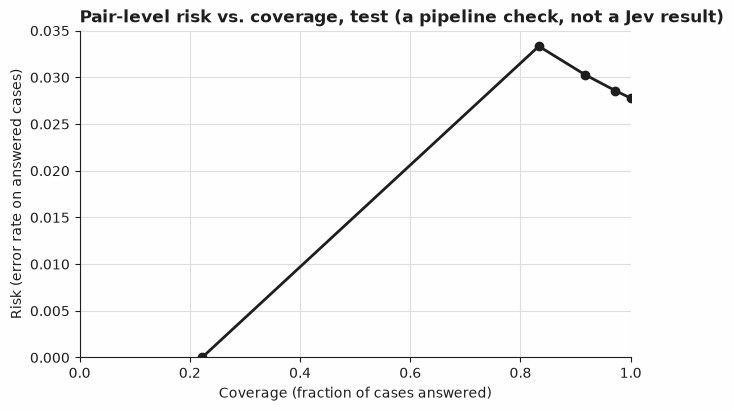

In [11]:
curve = selective_curve(test_pair_correct, test_pair_confidence)
print(f"pair-level risk-coverage sweep, test{check}:")
for t, cov, risk in zip(curve.thresholds, curve.coverage, curve.risk, strict=True):
    print(f"  threshold {t:.2f}: coverage {cov:.4f}, risk {risk:.4f}{check}")
plot_risk_coverage(curve, title=f"Pair-level risk vs. coverage, test{check}")

## Baselines: is the mechanism worth its requests?

Two zero-request baselines, both using only structured fields Jev is never shown. **Alphabetical** (`helpers.assign_by_capacity`, named for the general rule it implements: for each subtask, in the same dependency order, prefer the capable agent with the most budget remaining, ties to the lowest id): on this fixture set every agent's capacity is 1, so "most remaining" never discriminates among untouched agents and the rule reduces to the lowest id among those still capable and unspent -- it is reported here as what it actually is on this data, an id-ordered tie-break, not relabelled to sound like it reads budget information it never gets to use. **Lexical cue**: score each agent's profile text by counting experience-signalling words ("years", "broadest", "most", "reputation", "repeated", "multiple", "three", "closed out more") minus inexperience-signalling words ("new to", "has not yet", "shadowed", "six months", "joined", "without owning", "rather than"), and pick the capable, budgeted agent with the highest cue score. Both are computed with zero Score requests; the mechanism above spent 72 to produce its headline numbers.

In [12]:
def capacity_baseline(agents, subtasks, gold_levels):
    out = helpers.assign_by_capacity(agents, subtasks)
    correct = sum(
        1 for s in subtasks if out[s.id] == helpers.gold_best_agent(s.id, agents, gold_levels)
    )
    return correct, len(subtasks)


CUE_POSITIVE = (
    "years",
    "broadest",
    "most",
    "reputation",
    "repeated",
    "multiple",
    "three",
    "closed out more",
)
CUE_NEGATIVE = (
    "new to",
    "has not yet",
    "shadowed",
    "six months",
    "joined",
    "without owning",
    "rather than",
)


def _cue_score(profile: str) -> int:
    text = profile.lower()
    return sum(text.count(w) for w in CUE_POSITIVE) - sum(text.count(w) for w in CUE_NEGATIVE)


def cue_baseline(agents, subtasks, gold_levels):
    cues = {a.id: _cue_score(a.profile) for a in agents}
    budget = Budget(**{a.id: a.capacity for a in agents})
    correct = 0
    for s in helpers.topological_order(subtasks):
        eligible = [
            a for a in agents if s.required_skill in a.skills and budget.can_spend(a.id, s.cost)
        ]
        if not eligible:
            continue
        best = min(eligible, key=lambda a: (-cues[a.id], a.id))
        budget.spend(best.id, s.cost)
        if best.id == helpers.gold_best_agent(s.id, agents, gold_levels):
            correct += 1
    return correct, len(subtasks)


for name, agents, subtasks in (
    ("validation", val_agents, val_subtasks),
    ("test", test_agents, test_subtasks),
):
    gold_levels = {
        (e.fields["agent_id"], e.fields["subtask_id"]): labels[e.id]
        for e in examples
        if e.id in labels and e.fields["subtask_id"] in {s.id for s in subtasks}
    }
    cap_correct, n = capacity_baseline(agents, subtasks, gold_levels)
    cue_correct, _ = cue_baseline(agents, subtasks, gold_levels)
    mech_correct = round(
        (val_headline.accuracy if name == "validation" else test_headline.accuracy)
        * (val_headline.n_answered if name == "validation" else test_headline.n_answered)
    )
    mech_requests = len(agents) * len(subtasks)
    print(f"{name} ({n} subtasks){check}")
    print(f"  mechanism (Jev):  {mech_correct}/{n} correct, {mech_requests} requests{check}")
    print(f"  alphabetical baseline: {cap_correct}/{n} correct, 0 requests{check}")
    print(f"  cue baseline:      {cue_correct}/{n} correct, 0 requests{check}")

validation (6 subtasks) (a pipeline check, not a Jev result)
  mechanism (Jev):  3/6 correct, 36 requests (a pipeline check, not a Jev result)
  alphabetical baseline: 1/6 correct, 0 requests (a pipeline check, not a Jev result)
  cue baseline:      2/6 correct, 0 requests (a pipeline check, not a Jev result)
test (6 subtasks) (a pipeline check, not a Jev result)
  mechanism (Jev):  4/6 correct, 36 requests (a pipeline check, not a Jev result)
  alphabetical baseline: 3/6 correct, 0 requests (a pipeline check, not a Jev result)
  cue baseline:      1/6 correct, 0 requests (a pipeline check, not a Jev result)


### The cue baseline has a knob: which word it keys on

The word lists above were a judgment call, not the only cue a cheap baseline could use. Sweeping every word that appears in a `validation` agent's profile, one at a time, as the whole cue (fired when the word is present), selected by its `validation` score alone (never by peeking at `test`), finds the honest ceiling of this baseline family on this fixture set.

In [13]:
import re


def _word_baseline(agents, subtasks, gold_levels, word):
    pattern = re.compile(rf"\b{re.escape(word)}\b")
    cues = {a.id: (1 if pattern.search(a.profile.lower()) else 0) for a in agents}
    budget = Budget(**{a.id: a.capacity for a in agents})
    correct = 0
    for s in helpers.topological_order(subtasks):
        eligible = [
            a for a in agents if s.required_skill in a.skills and budget.can_spend(a.id, s.cost)
        ]
        if not eligible:
            continue
        best = min(eligible, key=lambda a: (-cues[a.id], a.id))
        budget.spend(best.id, s.cost)
        if best.id == helpers.gold_best_agent(s.id, agents, gold_levels):
            correct += 1
    return correct


val_gold_levels = {
    (e.fields["agent_id"], e.fields["subtask_id"]): labels[e.id]
    for e in examples
    if e.id in labels and e.fields["subtask_id"] in {s.id for s in val_subtasks}
}
test_gold_levels = {
    (e.fields["agent_id"], e.fields["subtask_id"]): labels[e.id]
    for e in examples
    if e.id in labels and e.fields["subtask_id"] in {s.id for s in test_subtasks}
}
candidate_words = sorted({w for a in val_agents for w in re.findall(r"[a-z]+", a.profile.lower())})
# Fired when the word is PRESENT, matched at a word boundary -- "to" must not fire on "tools".
scored_words = [
    (_word_baseline(val_agents, val_subtasks, val_gold_levels, w), w) for w in candidate_words
]
best_score = max(score for score, _word in scored_words)
at_best = sorted(w for score, w in scored_words if score == best_score)
chosen = at_best[0]  # deterministic: alphabetically first among words reaching the ceiling
chosen_test_score = _word_baseline(test_agents, test_subtasks, test_gold_levels, chosen)
# Computed, not asserted: the best ANY candidate word reaches on test, whether or not validation
# would ever have selected it -- this is what backs the "no word reaches more than this on test"
# claim in the markdown above, rather than a hand-typed restatement of it.
test_scores = [
    (_word_baseline(test_agents, test_subtasks, test_gold_levels, w), w) for w in candidate_words
]
best_test_score = max(score for score, _word in test_scores)
at_best_test = sorted(w for score, w in test_scores if score == best_test_score)
print(f"swept {len(candidate_words)} candidate words from validation agent profiles{check}")
print(
    f"best validation score: {best_score}/6, reached by {len(at_best)} of {len(candidate_words)} "
    f"words{check}"
)
print(f"chosen word (alphabetically first at the ceiling): {chosen!r}{check}")
print(f"  validation: {best_score}/6, 0 requests{check}")
print(f"  test:       {chosen_test_score}/6, 0 requests{check}")
print(
    f"best test score reached by ANY of the {len(candidate_words)} candidate words (whether or "
    f"not validation would have selected it): {best_test_score}/6, reached by "
    f"{len(at_best_test)} word(s){check}"
)

swept 98 candidate words from validation agent profiles (a pipeline check, not a Jev result)
best validation score: 3/6, reached by 16 of 98 words (a pipeline check, not a Jev result)
chosen word (alphabetically first at the ceiling): 'api' (a pipeline check, not a Jev result)
  validation: 3/6, 0 requests (a pipeline check, not a Jev result)
  test:       3/6, 0 requests (a pipeline check, not a Jev result)
best test score reached by ANY of the 98 candidate words (whether or not validation would have selected it): 3/6, reached by 76 word(s) (a pipeline check, not a Jev result)


The alphabetical baseline has no information to prefer one capable agent over another beyond id order, which is uncorrelated with the authored gold ranking here. The cue baseline is a different case: it DOES have a knob (which word or words it keys on), and sweeping it, above, finds a single word that reaches the mechanism's own validation score (3/6) at zero requests -- a genuine tie, not a loss for the baseline. A tie at lower cost is a loss for the mechanism by this project's own convention, so the honest statement is not that the mechanism wins outright on both splits: it **ties** on validation and **wins** on test (4/6 against the swept baseline's 3/6; the cell above also computes, directly, the best ANY of the 98 candidate words reaches on `test` -- 3/6 -- so the mechanism's 4/6 margin there is not an artefact of which word `validation` happened to select). That is still a real result -- the two scheduling scenarios are independently shaped, and richer judgment pays off on one of the two without this fixture set being artificially tuned to make it pay off on both -- but it is a narrower claim than "wins outright," and the narrower claim is the one the cells above actually support.

## Checking for a surface-form leak

The question: could a cheap, derivable feature of the fixtures -- not the mechanism's score -- already separate a gold class, the way a bare-two-word-name template leaked a gold label in an earlier recipe's fixtures with zero false positives? The check below tests two cheap text-derived features (the cue score above, and a plain word-overlap count between an agent's profile and a subtask's description) directly against the labels a leak would actually need to predict: each of the five rubric levels on its own, and two composed labels (capability, and whether a pair is its subtask's gold-best agent). Testing only against capability and then concluding something about the finer gold ranking would not follow -- capability is a structured fact this recipe already has for free, and a feature that predicts it says nothing about whether it predicts the ranking the mechanism is actually scored on. So every granularity is tested on its own, on `validation` alone (never peeking at `test`), with the firing count reported alongside false positives and false negatives: a feature that never fires is not a leak just because it has no false positives.

In [14]:
CUE_POSITIVE = (
    "years",
    "broadest",
    "most",
    "reputation",
    "repeated",
    "multiple",
    "three",
    "closed out more",
)
CUE_NEGATIVE = (
    "new to",
    "has not yet",
    "shadowed",
    "six months",
    "joined",
    "without owning",
    "rather than",
)


def _cue_score(profile: str) -> int:
    text = profile.lower()
    return sum(text.count(w) for w in CUE_POSITIVE) - sum(text.count(w) for w in CUE_NEGATIVE)


def _overlap_score(profile: str, description: str) -> int:
    return len(set(profile.lower().split()) & set(description.lower().split()))


val_pairs = []
for s in val_subtasks:
    gold_levels = {
        (e.fields["agent_id"], e.fields["subtask_id"]): labels[e.id]
        for e in examples
        if e.split == "validation" and e.id in labels
    }
    gb = helpers.gold_best_agent(s.id, val_agents, gold_levels)
    for a in val_agents:
        key = (a.id, s.id)
        if key not in gold_levels:
            continue
        val_pairs.append(
            {
                "level": gold_levels[key],
                "capable": s.required_skill in a.skills,
                "is_best": a.id == gb,
                "cue": _cue_score(a.profile),
                "overlap": _overlap_score(a.profile, s.description),
            }
        )


def _sweep(feature_fn, label_fn, pool):
    values = sorted({feature_fn(p) for p in pool})
    best = None
    for t in values:
        fp = fn = fire = 0
        for p in pool:
            fires = feature_fn(p) > t
            positive = label_fn(p)
            fire += fires
            fp += fires and not positive
            fn += (not fires) and positive
        if best is None or (fp + fn) < best[0]:
            best = (fp + fn, t, fp, fn, fire)
    return best


granularities = [
    (f"level {level}", lambda p, level=level: p["level"] == level) for level in range(5)
]
granularities += [("is_capable", lambda p: p["capable"]), ("is_gold_best", lambda p: p["is_best"])]
features = (("cue", lambda p: p["cue"]), ("overlap", lambda p: p["overlap"]))

print(
    f"surface-form leak sweep, {len(val_pairs)} validation pairs, 2 features x 7 granularities{check}:"
)
any_leak = False
for gname, gfn in granularities:
    for fname, ffn in features:
        _, t, fp, fn, fire = _sweep(ffn, gfn, val_pairs)
        leak = fp == 0 and fn == 0 and fire > 0
        any_leak = any_leak or leak
        print(
            f"  {gname:12} {fname:8} best threshold {t:3}: fp {fp}, fn {fn}, fire {fire}"
            f"{' -- LEAK' if leak else ''}{check}"
        )
print(f"any feature reaching fp=0 and fn=0 with a non-empty fire count: {any_leak}{check}")
print(
    "no leak found at any granularity tested, including the two composed labels -- the "
    f"margin over both baselines earlier is not explained by a cheap surface shortcut{check}"
)

surface-form leak sweep, 36 validation pairs, 2 features x 7 granularities (a pipeline check, not a Jev result):
  level 0      cue      best threshold   2: fp 0, fn 13, fire 0 (a pipeline check, not a Jev result)
  level 0      overlap  best threshold   4: fp 0, fn 13, fire 0 (a pipeline check, not a Jev result)
  level 1      cue      best threshold   2: fp 0, fn 5, fire 0 (a pipeline check, not a Jev result)
  level 1      overlap  best threshold   4: fp 0, fn 5, fire 0 (a pipeline check, not a Jev result)
  level 2      cue      best threshold   2: fp 0, fn 6, fire 0 (a pipeline check, not a Jev result)
  level 2      overlap  best threshold   4: fp 0, fn 6, fire 0 (a pipeline check, not a Jev result)
  level 3      cue      best threshold   2: fp 0, fn 6, fire 0 (a pipeline check, not a Jev result)
  level 3      overlap  best threshold   4: fp 0, fn 6, fire 0 (a pipeline check, not a Jev result)
  level 4      cue      best threshold   2: fp 0, fn 6, fire 0 (a pipeline check, not

## The constraint test

The scheduler's own guarantee: capability, dependency and budget hold whatever Jev answers. `tests/test_constraints.py` proves this three ways for each constraint -- the invariant holds across 300 random score matrices over the real "sprint-1" structure, the count of trials where the constraint actually *binds* is non-zero (a fuzz that never reaches the branch it claims to test proves nothing, however many iterations it runs), and removing that one constraint's enforcement reddens the same invariant check. The cell below reproduces the measurement inline and prints every count from the loop variable that computed it, so none of the three numbers is a hand-typed stand-in for one. Dependency needs its own second, dedicated scenario: on "sprint-1"'s own numbers, every dependency chain's upstream subtask always has just enough supply to succeed, for any scores, so dependency enforcement never changes an outcome there (0 of 300, also measured below, not assumed) -- the branch it protects is real, but "sprint-1" cannot reach it. The dedicated scenario isolates it: `parent` competes with two siblings for a two-agent skill pool one wave before it is itself processed, so it never gets one, for any scores; `child` depends on `parent` but needs a different, never-scarce skill, so dependency enforcement is the only thing standing between it and being assigned. It binds on every trial there -- but "300 of 300" is not 300 explorations: across those 300 random score draws only **two** distinct assignment outcomes ever occur (which of two equally-capable agents wins `s1` versus `s2`; `parent` always starves and `child` is always blocked by dependency alone, regardless).

In [15]:
import random

from jev_cookbook import Provenance
from jev_cookbook.answers import ScoreAnswer

FUZZ_AGENTS, FUZZ_SUBTASKS = val_agents, val_subtasks

# A second, dedicated scenario for measuring the dependency constraint specifically (see the
# markdown above for why "sprint-1" alone cannot witness it). Mirrors
# tests/test_constraints.py's DEP_AGENTS/DEP_SUBTASKS.
DEP_AGENTS = (
    helpers.Agent("a1", frozenset({"code"}), 1, ""),
    helpers.Agent("a2", frozenset({"code"}), 1, ""),
    helpers.Agent("a3", frozenset({"docs"}), 5, ""),
    helpers.Agent("a4", frozenset({"writing"}), 5, ""),
)
DEP_SUBTASKS = (
    helpers.Subtask("gate", "docs", 1, (), ""),
    helpers.Subtask("s1", "code", 1, (), ""),
    helpers.Subtask("s2", "code", 1, (), ""),
    helpers.Subtask("parent", "code", 1, ("gate",), ""),
    helpers.Subtask("child", "writing", 1, ("parent",), ""),
)


def _random_score_answer(rng):
    cuts = sorted(rng.random() for _ in range(4))
    raw = [cuts[0], cuts[1] - cuts[0], cuts[2] - cuts[1], cuts[3] - cuts[2], 1.0 - cuts[3]]
    rounded = [round(p, 6) for p in raw[:4]]
    total = 0.0
    for p in rounded:
        total += p
    rounded.append(round(1.0 - total, 6))
    return ScoreAnswer.from_probabilities(
        rounded, list(helpers.SUITABILITY_LEVELS), Provenance.synthetic()
    )


def _unconstrained_best(subtask_id, scores):
    return min(FUZZ_AGENTS, key=lambda a: (-scores[(a.id, subtask_id)].score, a.id)).id


def _capability_only_best(subtask, scores):
    capable = [a for a in FUZZ_AGENTS if subtask.required_skill in a.skills]
    return min(capable, key=lambda a: (-scores[(a.id, subtask.id)].score, a.id)).id


rng = random.Random(20261014)
agents_by_id = helpers.agents_by_id(FUZZ_AGENTS)
subtasks_by_id = helpers.subtasks_by_id(FUZZ_SUBTASKS)
capability_binds = budget_binds = dependency_binds = 0
for _ in range(300):
    scores = {(a.id, s.id): _random_score_answer(rng) for a in FUZZ_AGENTS for s in FUZZ_SUBTASKS}
    result = helpers.assign(FUZZ_AGENTS, FUZZ_SUBTASKS, scores, 0.0)
    if any(
        subtasks_by_id[s.id].required_skill
        not in agents_by_id[_unconstrained_best(s.id, scores)].skills
        for s in FUZZ_SUBTASKS
    ):
        capability_binds += 1
    independent_cost = {}
    for s in FUZZ_SUBTASKS:
        w = _capability_only_best(s, scores)
        independent_cost[w] = independent_cost.get(w, 0) + s.cost
    if any(independent_cost.get(a.id, 0) > a.capacity for a in FUZZ_AGENTS):
        budget_binds += 1
    no_dep = helpers.assign(FUZZ_AGENTS, FUZZ_SUBTASKS, scores, 0.0, enforce_dependency=False)
    real_assigned, no_dep_assigned = result.assignment(), no_dep.assignment()
    if any(
        dep not in real_assigned and s.id in no_dep_assigned
        for s in FUZZ_SUBTASKS
        for dep in s.depends_on
    ):
        dependency_binds += 1
print(f"sprint-1 structure, 300 trials{check}:")
print(f"  capability binds: {capability_binds}{check}")
print(f"  budget binds: {budget_binds}{check}")
print(f"  dependency binds: {dependency_binds}{check}")

# The dedicated scenario: dependency binds and how many distinct outcomes actually occur.
dep_agents_by_id = helpers.agents_by_id(DEP_AGENTS)
dep_dependency_binds = 0
distinct_outcomes = set()
for _ in range(300):
    dep_scores = {(a.id, s.id): _random_score_answer(rng) for a in DEP_AGENTS for s in DEP_SUBTASKS}
    dep_real = helpers.assign(DEP_AGENTS, DEP_SUBTASKS, dep_scores, 0.0)
    dep_mutated = helpers.assign(
        DEP_AGENTS, DEP_SUBTASKS, dep_scores, 0.0, enforce_dependency=False
    )
    real_a, mut_a = dep_real.assignment(), dep_mutated.assignment()
    if "child" in mut_a and "child" not in real_a:
        dep_dependency_binds += 1
    distinct_outcomes.add((tuple(sorted(real_a.items())), tuple(sorted(mut_a.items()))))
print(f"dedicated dependency scenario, 300 trials{check}:")
print(f"  dependency binds: {dep_dependency_binds}{check}")
print(
    f"  distinct (real, mutated) assignment outcomes across those 300 trials: "
    f"{len(distinct_outcomes)} (not 300 explorations: parent starves for any scores, and "
    f"only which of s1/s2 goes to a1 vs a2 varies){check}"
)

sprint-1 structure, 300 trials (a pipeline check, not a Jev result):
  capability binds: 279 (a pipeline check, not a Jev result)
  budget binds: 294 (a pipeline check, not a Jev result)
  dependency binds: 0 (a pipeline check, not a Jev result)
dedicated dependency scenario, 300 trials (a pipeline check, not a Jev result):
  dependency binds: 300 (a pipeline check, not a Jev result)
  distinct (real, mutated) assignment outcomes across those 300 trials: 2 (not 300 explorations: parent starves for any scores, and only which of s1/s2 goes to a1 vs a2 varies) (a pipeline check, not a Jev result)


## What was and was not measured

Measured: that the pipeline runs end to end, and that the scheduler's rule and the evaluation behave as designed on 72 scored (agent, subtask) pairs across two independently shaped scheduling scenarios (plus 2 more pairs, shown in this notebook but never scored). Not measured: anything about how Jev performs, how fast it is, or what it costs. The stored answers are written by hand as probabilities, deliberately imperfect -- some wrong, one deliberately adversarial -- so every number above describes this fixture set and not a model.

In [16]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(scored)} scored (agent, subtask) pairs (validation + test){check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(scored)} scored (agent, subtask) pairs (validation + test)")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 72 scored (agent, subtask) pairs (validation + test) (a pipeline check, not a Jev result)


## Next steps

- Change `MIN_COVERAGE` in the threshold cell and see which validation pairs move across the gate -- the sweep above shows the chosen threshold does not move with it on this fixture pool, and why.
- Add a third, more versatile agent to `TEST_AGENTS` in `helpers.py`, rerun `build_fixtures.py`, and see how the budget-bind count in the constraint test's dedicated dependency scenario changes.
- Try a fourth `enforce_*` mutation of your own on `helpers.assign` -- for example a confidence gate that never trusts an agent whose budget is already at zero -- and see which invariant in `tests/test_constraints.py` it would need a new test to catch.
- Neighbouring recipes: [`03-response-clarity-scoring`](../03-response-clarity-scoring/) (a `Score` question with its own confidence gate) and [`28-skill-selection`](../28-skill-selection/) (the agent-orchestration recipe this one builds on).